<a href="https://colab.research.google.com/github/25523072-glitch/ADA-Team-Tugas-FSD/blob/main/A_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bagian A: Linear Regression
**Prediksi nilai transaksi (revenue) penjualan coffee shop**

Anggota: Ahmad Azzuri Pakalessy (25523120), Muhammad Pramudya Aldiansyah (25523082), Danis Setiyawan (25523072)


## A1. Deskripsi Dataset
- **Sumber:** Coffee Shop Sales (Maven Roasters), Kaggle : https://www.kaggle.com/datasets/ahmedabbas757/coffee-sales. Transaksi 3 toko di New York, Jan–Jun 2023
- **Ukuran:** 149.116 baris x 11 kolom
- **Kolom asli:** transaction_id, transaction_date, transaction_time, transaction_qty, store_id, store_location, product_id, unit_price, product_category, product_type, product_detail
- **Target:** revenue = transaction_qty x unit_price (USD per transaksi), numerik kontinu
- **Fitur model:** unit_price, hour, is_weekend, month (dari tanggal/jam), store_location, product_category
- **Tidak dipakai:** transaction_qty (komponen target, kebocoran data), kolom ID, product_type dan product_detail (kategori terlalu banyak)

In [9]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style('whitegrid')
RS = 42

# Upload file dataset ke panel Files Colab
kandidat = ['/content/Coffee Shop Sales.xlsx', '/content/Coffee Shop Sales.csv',
            'data/Coffee Shop Sales.xlsx', 'data/Coffee Shop Sales.csv',
            'Coffee Shop Sales.xlsx', 'Coffee Shop Sales.csv']
path = next((p for p in kandidat if os.path.exists(p)), None)
assert path, 'File dataset tidak ditemukan. Upload Coffee Shop Sales.xlsx/.csv ke Colab.'
df_a = pd.read_excel(path) if path.endswith('.xlsx') else pd.read_csv(path)

# Target dan fitur turunan
df_a['revenue'] = df_a['transaction_qty'] * df_a['unit_price']
df_a['hour'] = df_a['transaction_time'].astype(str).str[:2].astype(int)
tgl = pd.to_datetime(df_a['transaction_date'])
df_a['is_weekend'] = (tgl.dt.dayofweek >= 5).astype(int)
df_a['month'] = tgl.dt.month

print('Jumlah baris dan kolom (asli):', df_a.shape[0], 'x', df_a.shape[1] - 4)
display(df_a.head())
df_a.info()

Jumlah baris dan kolom (asli): 149116 x 11


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail,revenue,hour,is_weekend,month
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg,6.0,7,1,1
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2,7,1,1
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg,9.0,7,1,1
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm,2.0,7,1,1
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,6.2,7,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  object        
 9   product_type      149116 non-null  object        
 10  product_detail    149116 non-null  object        
 11  revenue           149116 non-null  float64       
 12  hour              149116 non-null  int64         
 13  is_weekend        149116 non-null  int64         
 14  mont

## A2. Eksplorasi dan Visualisasi Data
Statistik deskriptif, lalu empat visualisasi: histogram target, heatmap korelasi, scatter unit_price vs revenue, dan boxplot revenue per kategori produk

,revenue,transaction_qty,unit_price,hour,is_weekend,month
count,149116.000,149116.000,149116.000,149116.000,149116.000,149116.000
mean,4.686,1.438,3.382,11.736,0.279,3.989
std,4.227,0.543,2.659,3.765,0.449,1.673
min,0.800,1.000,0.800,6.000,0.000,1.000
25%,3.000,1.000,2.500,9.000,0.000,3.000
50%,3.750,1.000,3.000,11.000,0.000,4.000
75%,6.000,2.000,3.750,15.000,1.000,5.000
max,360.000,8.000,45.000,20.000,1.000,6.000


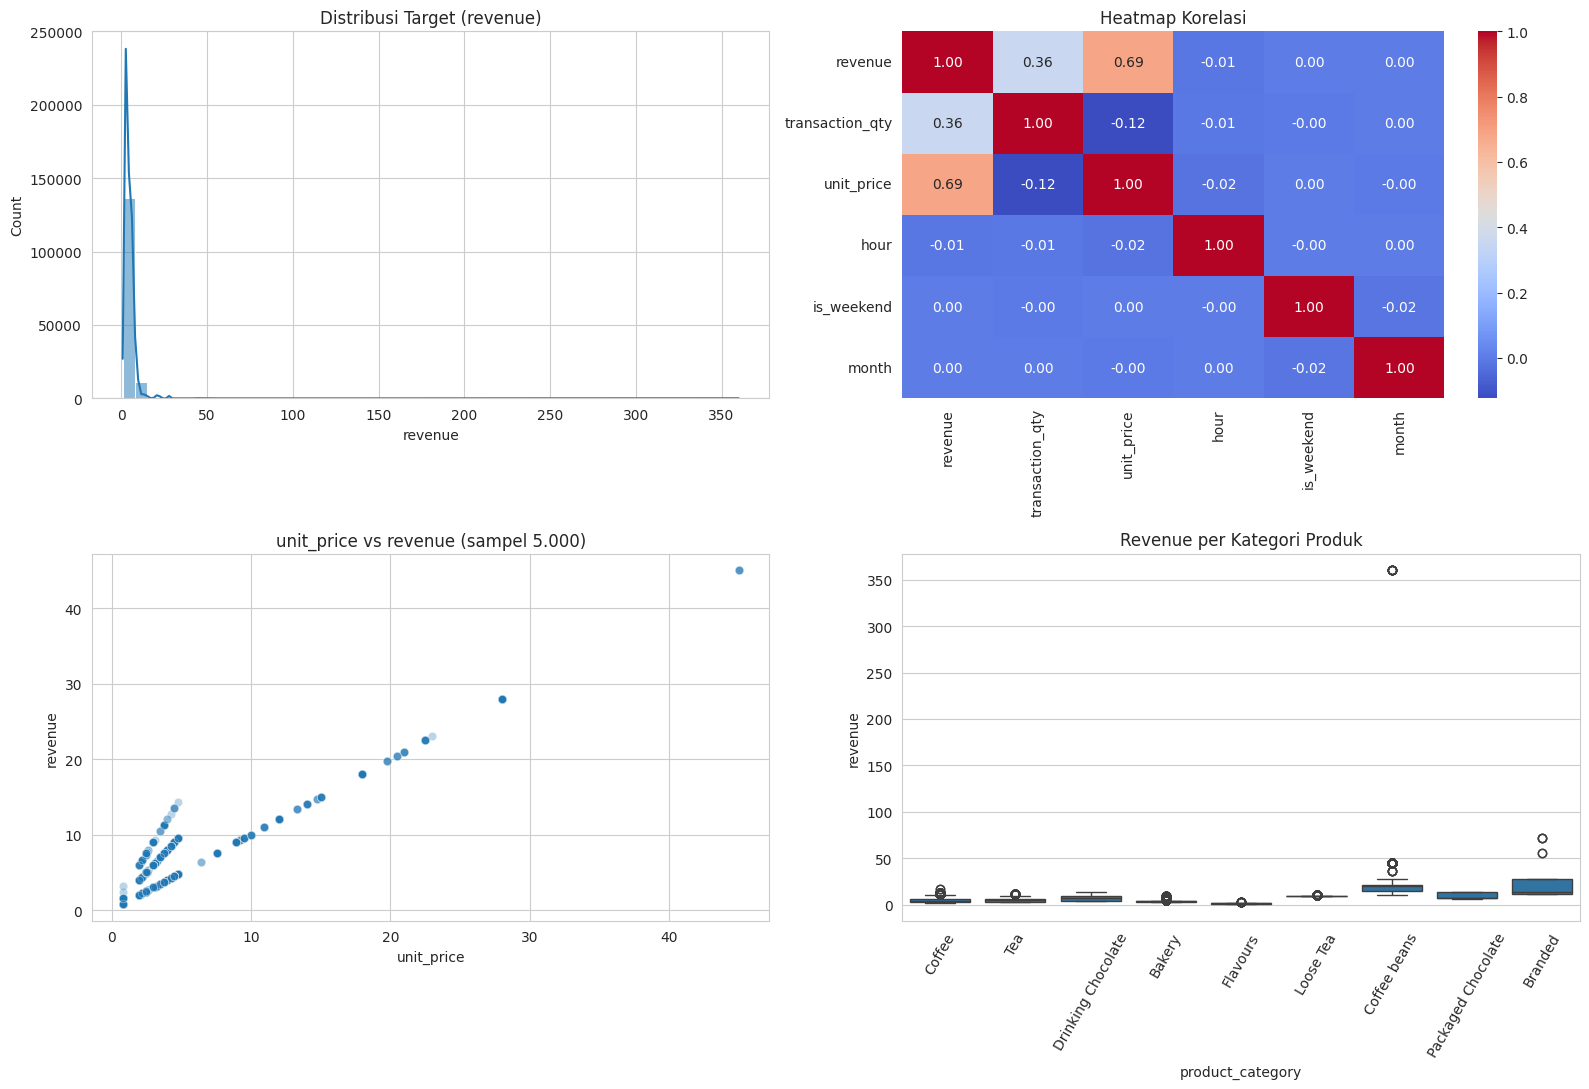

Korelasi dengan revenue:
unit_price         0.686
transaction_qty    0.356
hour              -0.014
month              0.001
is_weekend         0.001
Name: revenue, dtype: float64


In [10]:
display(df_a[['revenue', 'transaction_qty', 'unit_price', 'hour', 'is_weekend', 'month']].describe().round(3))

fig, ax = plt.subplots(2, 2, figsize=(16, 11))
sns.histplot(df_a['revenue'], bins=50, kde=True, ax=ax[0, 0])
ax[0, 0].set_title('Distribusi Target (revenue)')

kol_num_eda = ['revenue', 'transaction_qty', 'unit_price', 'hour', 'is_weekend', 'month']
sns.heatmap(df_a[kol_num_eda].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[0, 1])
ax[0, 1].set_title('Heatmap Korelasi')

samp = df_a.sample(5000, random_state=RS)
sns.scatterplot(x='unit_price', y='revenue', data=samp, alpha=.3, ax=ax[1, 0])
ax[1, 0].set_title('unit_price vs revenue (sampel 5.000)')

sns.boxplot(x='product_category', y='revenue', data=df_a, ax=ax[1, 1])
ax[1, 1].tick_params(axis='x', rotation=60)
ax[1, 1].set_title('Revenue per Kategori Produk')
plt.tight_layout(); plt.show()

print('Korelasi dengan revenue:')
print(df_a[kol_num_eda].corr()['revenue'].drop('revenue').sort_values(key=abs, ascending=False).round(3))

**Temuan A2:**
- **Histogram:** revenue condong ke kanan ; mayoritas transaksi bernilai kecil, sebagian kecil sangat besar
- **Heatmap:** unit_price paling berkorelasi dengan revenue; hour, is_weekend, month lemah
- **Scatter:** pola garis-garis menyebar dari titik nol, karena revenue = harga x jumlah
- **Boxplot:** revenue berbeda antar kategori; kategori berharga mahal (mis. Coffee beans, Packaged Chocolate) memiliki nilai tertinggi

## A3. Preprocessing
- **Missing values & duplikat:** diperiksa dan dihapus bila ada
- **Outlier:** dideteksi dengan IQR pada target, **tidak dihapus** karena berasal dari produk yang memang mahal (nilai valid, bukan salah input) ; dampaknya dibahas di A8
- **Encoding:** One-Hot (drop_first=True) untuk store_location dan product_category
- **Scaling:** StandardScaler pada fitur numerik, dijalankan setelah split (A5) agar tidak terjadi data leakage

In [11]:
df_bersih = df_a.copy()
print('Missing values total:', int(df_bersih.isnull().sum().sum()))
df_bersih = df_bersih.dropna()
print('Baris duplikat:', int(df_bersih.duplicated().sum()))
df_bersih = df_bersih.drop_duplicates()

# Outlier (IQR) pada target dan unit_price: hanya dilaporkan
for kol in ['revenue', 'unit_price']:
    q1, q3 = df_bersih[kol].quantile([.25, .75])
    iqr = q3 - q1
    b, a = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((df_bersih[kol] < b) | (df_bersih[kol] > a)).sum())
    print(f'{kol}: batas [{b:.2f}, {a:.2f}] | outlier = {n} ({n/len(df_bersih):.1%}) | dipertahankan')

fitur_num = ['unit_price', 'hour', 'is_weekend', 'month']
fitur_kat = ['store_location', 'product_category']
df_enc = pd.get_dummies(df_bersih[fitur_num + fitur_kat + ['revenue']],
                        columns=fitur_kat, drop_first=True, dtype=int)
print('Ukuran data setelah encoding:', df_enc.shape)
display(df_enc.head())

Missing values total: 0
Baris duplikat: 0
revenue: batas [-1.50, 10.50] | outlier = 3273 (2.2%) | dipertahankan
unit_price: batas [0.62, 5.62] | outlier = 4212 (2.8%) | dipertahankan
Ukuran data setelah encoding: (149116, 15)


,unit_price,hour,is_weekend,month,revenue,store_location_Hell's Kitchen,store_location_Lower Manhattan,product_category_Branded,product_category_Coffee,product_category_Coffee beans,product_category_Drinking Chocolate,product_category_Flavours,product_category_Loose Tea,product_category_Packaged Chocolate,product_category_Tea
0,3.0,7,1,1,6.0,0,1,0,1,0,0,0,0,0,0
1,3.1,7,1,1,6.2,0,1,0,0,0,0,0,0,0,1
2,4.5,7,1,1,9.0,0,1,0,0,0,1,0,0,0,0
3,2.0,7,1,1,2.0,0,1,0,1,0,0,0,0,0,0
4,3.1,7,1,1,6.2,0,1,0,0,0,0,0,0,0,1


## A4. Pemilihan Fitur
Tiga analisis: korelasi dengan target, uji F (f_regression, setara SelectKBest), dan VIF (multikolinearitas)

**Aturan:**

(1) buang fitur dengan p-value uji F >= 0,05;

(2) selama masih ada fitur ber-VIF >= 10, buang satu fitur ber-VIF tinggi yang skor F-nya paling rendah, lalu hitung ulang VIF

Analisis ini eksploratif; model akhir tetap dievaluasi pada data uji terpisah

,korelasi,skor_F,p_value,VIF_awal,status
unit_price,0.6855,132221.6002,0.0000,4.9161,dipertahankan
product_category_Coffee beans,0.4691,42069.0270,0.0000,3.4462,dipertahankan
product_category_Branded,0.2271,8108.7252,0.0000,1.8285,dipertahankan
product_category_Flavours,-0.1782,4888.2631,0.0000,1.4954,dipertahankan
product_category_Drinking Chocolate,0.1112,1866.3672,0.0000,1.4069,dipertahankan
product_category_Loose Tea,0.0980,1446.6489,0.0000,1.2157,dipertahankan
product_category_Packaged Chocolate,0.0591,522.6324,0.0000,1.0742,dipertahankan
product_category_Tea,-0.0572,488.7771,0.0000,2.1267,dipertahankan
store_location_Lower Manhattan,0.0209,64.8616,0.0000,1.3697,dipertahankan
hour,-0.0138,28.3330,0.0000,1.0429,dipertahankan


Dipertahankan: ['unit_price', 'hour', 'store_location_Lower Manhattan', 'product_category_Branded', 'product_category_Coffee', 'product_category_Coffee beans', 'product_category_Drinking Chocolate', 'product_category_Flavours', 'product_category_Loose Tea', 'product_category_Packaged Chocolate', 'product_category_Tea']
Dibuang      : {'is_weekend': 'p-value >= 0,05', 'month': 'p-value >= 0,05', "store_location_Hell's Kitchen": 'p-value >= 0,05'}


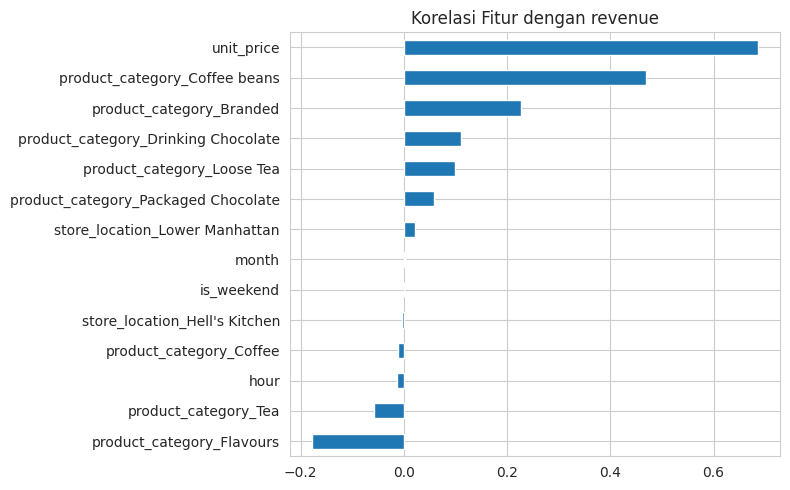

In [12]:
X_all = df_enc.drop(columns='revenue')
y_all = df_enc['revenue']
F, p = f_regression(X_all, y_all)
skor_F = pd.Series(F, index=X_all.columns)
Xs_all = X_all.sample(20000, random_state=RS).astype(float)

def hitung_vif(cols):
    Xs = sm.add_constant(Xs_all[cols])
    return pd.Series([variance_inflation_factor(Xs.values, i + 1) for i in range(len(cols))], index=cols)

tabel = pd.DataFrame({'korelasi': X_all.corrwith(y_all), 'skor_F': F, 'p_value': p,
                      'VIF_awal': hitung_vif(list(X_all.columns))}, index=X_all.columns)
alasan = {c: 'p-value >= 0,05' for c in tabel.index[tabel['p_value'] >= 0.05]}
sisa = [c for c in X_all.columns if c not in alasan]
while sisa:
    v = hitung_vif(sisa)
    tinggi = v[v >= 10]
    if tinggi.empty:
        break
    buang = skor_F[tinggi.index].idxmin()
    alasan[buang] = f'multikolinearitas (VIF {v[buang]:.1f})'
    sisa.remove(buang)

tabel['status'] = [alasan.get(c, 'dipertahankan') for c in tabel.index]
display(tabel.sort_values('skor_F', ascending=False).round(4))

fitur_terpilih = sisa
print('Dipertahankan:', fitur_terpilih)
print('Dibuang      :', alasan)

tabel['korelasi'].sort_values().plot(kind='barh', figsize=(8, 5), title='Korelasi Fitur dengan revenue')
plt.tight_layout(); plt.show()

**Temuan A4:** fitur yang dibuang (jika ada) tercantum pada output di atas beserta alasannya (p-value tinggi atau VIF >= 10). Fitur lainnya dipertahankan

## A5. Pembagian Data
Split 80:20 dengan train_test_split (random_state=42), lalu StandardScaler di-fit hanya pada data latih

In [13]:
X = X_all[fitur_terpilih].copy()
y = y_all
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS)

kol_scale = [c for c in fitur_num if c in X.columns]
if kol_scale:
    scaler = StandardScaler()
    X_train[kol_scale] = scaler.fit_transform(X_train[kol_scale])
    X_test[kol_scale] = scaler.transform(X_test[kol_scale])
print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)

Data latih: (119292, 11) | Data uji: (29824, 11)


## A6. Pemodelan

Intercept: 3.2694


,fitur,koefisien
0,product_category_Branded,-6.5021
1,product_category_Coffee beans,-6.4308
2,unit_price,3.9910
3,product_category_Loose Tea,-2.8684
4,product_category_Packaged Chocolate,-2.8508
5,product_category_Drinking Chocolate,1.8221
6,product_category_Tea,1.8168
7,product_category_Coffee,1.8103
8,product_category_Flavours,1.7121
9,store_location_Lower Manhattan,0.2638


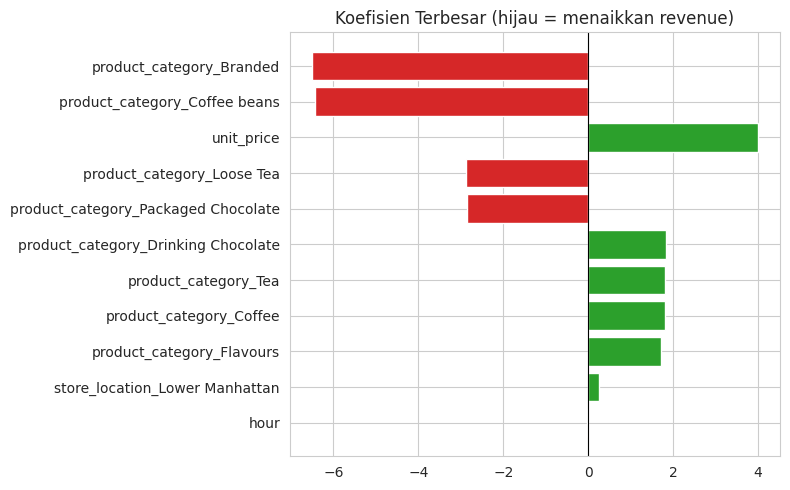

In [14]:
model = LinearRegression().fit(X_train, y_train)
print('Intercept:', round(model.intercept_, 4))
koef = (pd.DataFrame({'fitur': X.columns, 'koefisien': model.coef_})
        .assign(abs_k=lambda d: d['koefisien'].abs())
        .sort_values('abs_k', ascending=False).drop(columns='abs_k').reset_index(drop=True))
display(koef.round(4))

top = koef.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top['fitur'], top['koefisien'], color=np.where(top['koefisien'] > 0, 'tab:green', 'tab:red'))
plt.axvline(0, color='k', lw=.8); plt.title('Koefisien Terbesar (hijau = menaikkan revenue)')
plt.tight_layout(); plt.show()

**Interpretasi koefisien :**
- **Intercept:** prediksi revenue (USD) untuk kategori/toko acuan (yang di-*drop*) dengan fitur numerik di rata-rata
- **Fitur numerik** (di-scale): koefisien = perubahan revenue per kenaikan 1 simpangan baku fitur, dengan fitur lain tetap
- **Dummy:** koefisien = selisih revenue (USD) dibanding kategori/toko acuan. Positif menaikkan, negatif menurunkan

## A7. Evaluasi

,Latih,Uji
MAE,1.3803,1.3520
MSE,10.4070,2.6776
RMSE,3.2260,1.6363
R2,0.4809,0.7071


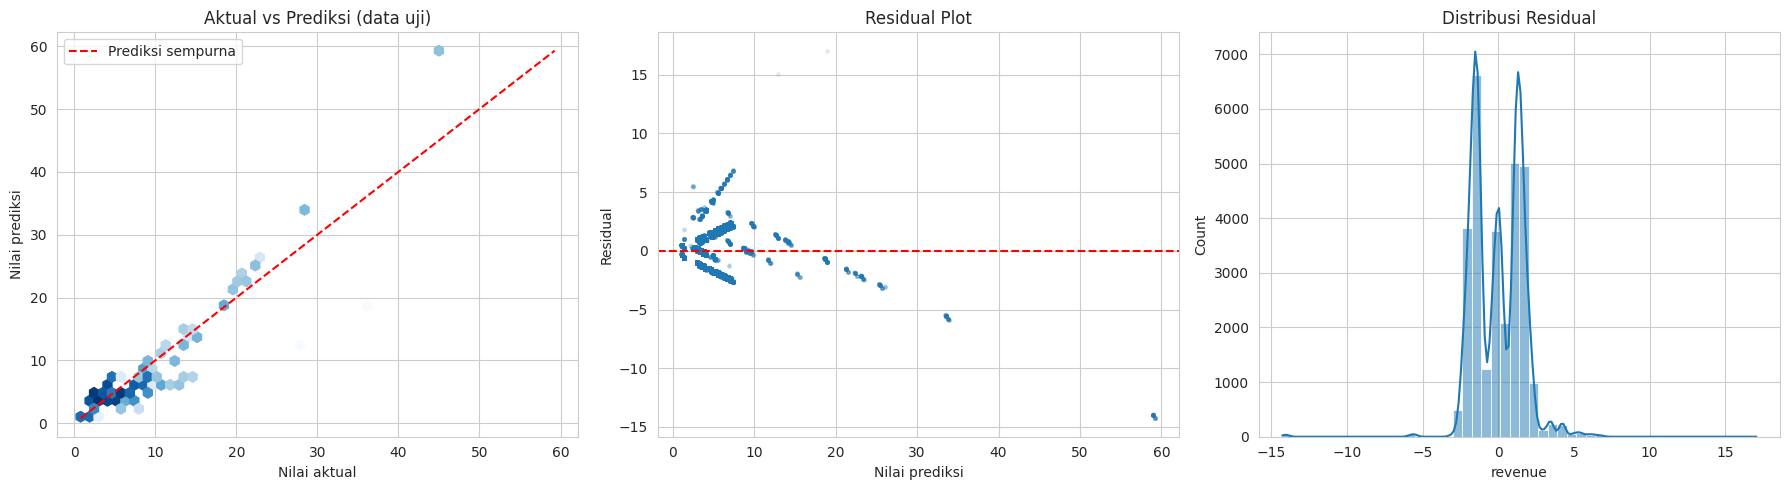

In [15]:
def evaluasi(y_asli, y_pred):
    mse = mean_squared_error(y_asli, y_pred)
    return {'MAE': mean_absolute_error(y_asli, y_pred), 'MSE': mse,
            'RMSE': np.sqrt(mse), 'R2': r2_score(y_asli, y_pred)}

pred_train, pred_test = model.predict(X_train), model.predict(X_test)
hasil = pd.DataFrame({'Latih': evaluasi(y_train, pred_train), 'Uji': evaluasi(y_test, pred_test)}).round(4)
display(hasil)

resid = y_test - pred_test
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].hexbin(y_test, pred_test, gridsize=40, cmap='Blues', mincnt=1, bins='log')
lim = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ax[0].plot(lim, lim, 'r--', label='Prediksi sempurna')
ax[0].set(xlabel='Nilai aktual', ylabel='Nilai prediksi', title='Aktual vs Prediksi (data uji)'); ax[0].legend()
ax[1].scatter(pred_test, resid, alpha=.1, s=6); ax[1].axhline(0, color='r', ls='--')
ax[1].set(xlabel='Nilai prediksi', ylabel='Residual', title='Residual Plot')
sns.histplot(resid, bins=50, kde=True, ax=ax[2]); ax[2].set_title('Distribusi Residual')
plt.tight_layout(); plt.show()

**Temuan A7:** bandingkan metrik latih vs uji pada tabel; plot aktual vs prediksi menunjukkan seberapa dekat titik ke garis diagonal; residual plot dan histogram residual menunjukkan pola error

## A8. Analisis Performa
Kesimpulan di bawah dihitung otomatis dari hasil run, sehingga selalu sesuai output

In [16]:
r2_tr, r2_te = hasil.loc['R2', 'Latih'], hasil.loc['R2', 'Uji']
rmse_te, sd_y = hasil.loc['RMSE', 'Uji'], y_test.std()
gap = r2_tr - r2_te

print(f'Kemampuan prediksi: R2 uji = {r2_te:.3f} (model menjelaskan {r2_te*100:.1f}% variasi revenue); '
      f'RMSE uji = {rmse_te:.3f} USD vs simpangan baku target {sd_y:.3f} USD.')
if gap > 0.05:
    diag = f'OVERFITTING (R2 latih {r2_tr:.3f} jauh di atas R2 uji {r2_te:.3f}).'
elif r2_tr < 0.5 and r2_te < 0.5:
    diag = f'UNDERFITTING (R2 latih {r2_tr:.3f} dan uji {r2_te:.3f} sama-sama rendah).'
else:
    diag = f'TIDAK ADA OVERFITTING/UNDERFITTING BERARTI (R2 latih {r2_tr:.3f} ~ uji {r2_te:.3f}, selisih {gap:.3f}).'
print('Overfitting/underfitting:', diag)
print('Fitur paling berpengaruh (|koefisien|):', ', '.join(koef['fitur'].head(3)))
print('Pred. negatif pada data uji:', int((pred_test < 0).sum()), 'baris (revenue nyata tidak mungkin negatif).')

Kemampuan prediksi: R2 uji = 0.707 (model menjelaskan 70.7% variasi revenue); RMSE uji = 1.636 USD vs simpangan baku target 3.024 USD.
Overfitting/underfitting: TIDAK ADA OVERFITTING/UNDERFITTING BERARTI (R2 latih 0.481 ~ uji 0.707, selisih -0.226).
Fitur paling berpengaruh (|koefisien|): product_category_Branded, product_category_Coffee beans, unit_price
Pred. negatif pada data uji: 0 baris (revenue nyata tidak mungkin negatif).


**Keterbatasan model:**
- Hubungan linear saja; interaksi harga x jumlah dan hubungan non-linear tidak tertangkap
- Target condong ke kanan dan outlier (produk mahal) menarik garis regresi; residual tidak simetris dan variansnya tidak konstan
- Tidak ada data pelanggan/promo; data hanya 6 bulan dan 3 toko, sehingga sulit digeneralisasi
- Prediksi linear bisa bernilai negatif